# Assignment **2** | ***1905074***
---

In [169]:
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### LR

In [170]:
class LR:
    def __init__(self, step=0.1, nItr=1000):
        self.step = step
        self.nItr = nItr
        self.w = None
        self.b = None

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))
    
    def predict_all(self, X):
        z = np.dot(X, self.w) + self.b
        y_pred = self.sigmoid(z)

        return y_pred

    def fit(self, X, y):
        self.w = np.zeros(X.shape[1])
        self.b = 0
    

        for _ in range(self.nItr):
            y_pred = self.predict_all(X)
            self.w -= self.step * np.dot(X.T, y_pred - y) / X.shape[0]
            self.b -= self.step * np.mean(y_pred - y)

    def predict(self, X):
        y_pred = self.predict_all(X)
        return np.where(y_pred >= 0.5, 1, 0)




### DataProcessing

In [171]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler,StandardScaler

In [172]:
def features_map(lst: list):
  return {j:i for i,j in enumerate(lst)}

In [173]:
def dataset1():
  df = pd.read_csv('D:\\4-2\\CSE 472 - ML\\Assignment 2\\Datasets\\WA_Fn-UseC_-Telco-Customer-Churn.csv')
  del df['customerID']
  df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
  df['TotalCharges'] = df['TotalCharges'].astype(float)
  df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].mean())
  df.replace('No internet service' , 'No' , inplace = True) 
  df['MultipleLines'] = df['MultipleLines'].replace('No phone service' , 'No')
  df.drop_duplicates(inplace=True)
  binary_columns = ['gender' , 'Partner' , 'Dependents' , 'PhoneService' , 'MultipleLines' , 'OnlineSecurity' , 'OnlineBackup' , 'DeviceProtection' , 'TechSupport' , 'StreamingTV' , 'StreamingMovies' , 'PaperlessBilling' , 'Churn']
  label_encoder = LabelEncoder() 
  for column in binary_columns:
      df[column] = label_encoder.fit_transform(df[column])
  # df[df.select_dtypes(include=['object']).columns] = df.select_dtypes(include=['object']).apply(lambda x: x.astype('category'))
  # df = pd.get_dummies(df) 
  object_columns = df.select_dtypes(include=['object']).columns
  for i in object_columns:
    df[i] = df[i].map(features_map(df[i].unique()))
  scaler = StandardScaler()
  columns_to_scale = ['tenure' , 'MonthlyCharges' , 'TotalCharges']
  df[columns_to_scale] = scaler.fit_transform(df[columns_to_scale])

  

  return df

In [174]:
def dataset2():
  column_names = [
        'age', 'workclass', 'fnlwgt', 'education', 'education-num',
        'marital-status', 'occupation', 'relationship', 'race',
        'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
    ]
  train_df=pd.read_csv('D:\\4-2\\CSE 472 - ML\\Assignment 2\\Datasets\\adult\\adult.data',na_values=' ?',header=None,names=column_names,skiprows=1)
  test_df = pd.read_csv('D:\\4-2\\CSE 472 - ML\\Assignment 2\\Datasets\\adult\\adult.test',na_values=' ?',header=None,names=column_names,skiprows=1)

  df = pd.concat([train_df, test_df], ignore_index=True)
  
  
  df.drop_duplicates(inplace=True)
  df['income'] = df['income'].map({
      '<=50K': 0,
      '>50K': 1,
      '>50K.': 1,
      '<=50K.': 0,
  })
  df = df.dropna()
  df['income']=df['income'].astype(int)
  # df = df.apply(lambda x : x.fillna(x.mode()[0]))
  # for i in df.select_dtypes(include='object').columns:
  #   df[i] = df[i].map(features_map(df[i].unique()))
  return df

In [175]:
def dataset3():
    df = pd.read_csv('D:\\4-2\\CSE 472 - ML\\Assignment 2\\Datasets\\creditcard.csv')
    df.drop_duplicates(inplace=True)  
    #sampling 20000 data with all true occurence
    true_rows = df[df['Class'] == True]
    no_of_false_rows = 20000 - true_rows.shape[0]
    sampled_false_rows = df[df['Class'] == False].sample(n=no_of_false_rows , random_state=42)
    minimized_sample = pd.concat([true_rows,sampled_false_rows])
    return minimized_sample

In [176]:
from sklearn.model_selection import train_test_split

In [177]:
def datasetnew():
    df= pd.read_csv('D:\\4-2\\CSE 472 - ML\\Assignment 2\\Datasets\\B1.csv')
    return df

In [178]:
# df.describe()

In [179]:

# # print(df)
# X = df[['X1', 'X2']].values
# y = df['y'].values

# # Split the data into training and test sets
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# # Plot the dataset (optional for visualization)
# plt.scatter(X[y == 0][:, 0], X[y == 0][:, 1], label='Class 0', alpha=0.6)
# plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], label='Class 1', alpha=0.6)
# plt.legend()
# plt.show()

In [180]:
from sklearn.preprocessing import StandardScaler
def select_dataset(n):
    if n==1:
        df= dataset1()
        return df.drop('Churn', axis=1), df['Churn']
    elif n==2:
        df= dataset2()
        features = df.drop('income',axis=1)
        labels = df['income']
        features[features.select_dtypes(include=['object']).columns] = features.select_dtypes(include=['object']).apply(lambda x: x.astype('category'))
        features = pd.get_dummies(features) #one hot encoding
        scaler = StandardScaler()
        numerical_columns = features.select_dtypes(include=["number"]).columns
        features[numerical_columns] = scaler.fit_transform(features[numerical_columns])
        # features = features.astype(float)
        return features , labels
    elif n==3:
        df= dataset3()
        features = df.drop('Class',axis=1)
        labels = df['Class']
        scaler = StandardScaler()
        features = pd.DataFrame(scaler.fit_transform(features) , columns=features.columns)
        features = features.astype(float)
        return features,labels
    elif n==4:
        df = datasetnew()
        X = df[['X1', 'X2']].values
        y = df['y'].values
        return X,y
        
    

In [181]:

from sklearn.utils import resample

In [182]:

X, y = select_dataset(1)
train_x, test_x, train_y, test_y = train_test_split(X, y, test_size=0.2, random_state=42)
train_x, val_x, train_y, val_y = train_test_split(train_x, train_y, test_size=0.2, random_state=42)

### Bagging

In [183]:
train_xs = []
train_ys = []

for i in range(9):
  tx, ty= resample(train_x, train_y, n_samples=len(train_x)//9, random_state=42 + i, stratify=train_y)
  train_xs.append(tx.copy())
  train_ys.append(ty.copy())

### Model

In [184]:
models = []
for i in range(9):
  model = LR(step=.1)
  model.fit(train_xs[i], train_ys[i])
  models.append(model)

In [185]:


from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix

In [186]:
def eval(y_given, y_proba):
  y_pred = y_proba >= 0.5

  accuracy = accuracy_score(y_given, y_pred)
  precision = precision_score(y_given, y_pred)
  sensitivity = recall_score(y_given, y_pred,pos_label=1)
  specificity = recall_score(y_given, y_pred,pos_label=0)
  f1 = f1_score(y_given, y_pred)
  auroc = roc_auc_score(y_given, y_proba)
  aupr = average_precision_score(y_given, y_proba)

  

  return {
      'Accuracy': accuracy,
      'Sensitivity': sensitivity,
      'Specificity': specificity,
      'Precision': precision,
      'F1-score': f1,
      'AUROC': auroc,
      'AUPR': aupr
  }

<Axes: >

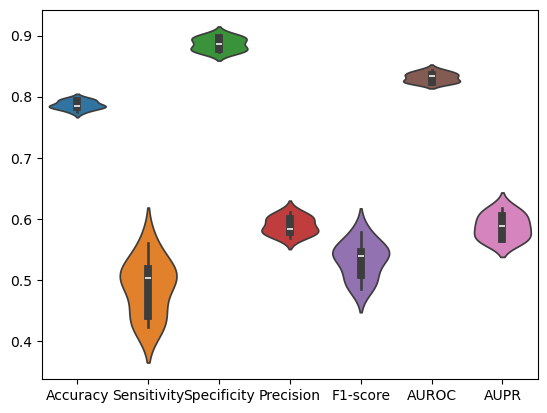

In [187]:
all_metrics = []

for i in range(9):
  y_pred = models[i].predict_all(test_x)
  metrics = eval(test_y, y_pred)
  metrics['Model'] = f'Model: {i+1}'
  all_metrics.append(metrics)
metrics_df = pd.DataFrame(all_metrics)
metrics_df.set_index('Model', inplace=True)
sns.violinplot(data=metrics_df)

### Majority Voting

In [188]:
preds_test = []
preds_val = []
for i in range(9):
  preds_test.append(models[i].predict(test_x))
  preds_val.append(models[i].predict(val_x))

preds_test = np.vstack(preds_test).T
preds_val = np.vstack(preds_val).T

In [189]:
preds_test

array([[1, 1, 1, ..., 1, 0, 1],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [190]:
from scipy.stats import mode
pred_test_final = mode(preds_test, axis=1)[0].flatten()  # Final majority-voted predictions for test set

In [191]:
voting_metric = eval(test_y, pred_test_final)
voting_metric

{'Accuracy': 0.79644128113879,
 'Sensitivity': 0.5056818181818182,
 'Specificity': 0.8936372269705603,
 'Precision': 0.6137931034482759,
 'F1-score': 0.5545171339563862,
 'AUROC': 0.6996595225761894,
 'AUPR': 0.4342274289092917}

### Stacking

In [192]:
meta_model = LR()
meta_model.fit(preds_val, val_y)

In [193]:
pred = meta_model.predict_all(preds_test)
stacking_metric = eval(test_y, pred)
stacking_metric

{'Accuracy': 0.7814946619217081,
 'Sensitivity': 0.44886363636363635,
 'Specificity': 0.8926875593542261,
 'Precision': 0.5830258302583026,
 'F1-score': 0.507223113964687,
 'AUROC': 0.7558275058275058,
 'AUPR': 0.525535472130424}

### Report

In [194]:
lr_metrics = metrics_df.mean().to_dict()
lr_metrics['Method'] = 'LR'
lr_metrics['Accuracy'] = f"{lr_metrics['Accuracy']:.3f} ± {metrics_df['Accuracy'].std():.3f}"
lr_metrics['Sensitivity'] = f"{lr_metrics['Sensitivity']:.3f} ± {metrics_df['Sensitivity'].std():.3f}"
lr_metrics['Specificity'] = f"{lr_metrics['Specificity']:.3f} ± {metrics_df['Specificity'].std():.3f}"
lr_metrics['Precision'] = f"{lr_metrics['Precision']:.3f} ± {metrics_df['Precision'].std():.3f}"
lr_metrics['F1-score'] = f"{lr_metrics['F1-score']:.3f} ± {metrics_df['F1-score'].std():.3f}"
lr_metrics['AUROC'] = f"{lr_metrics['AUROC']:.3f} ± {metrics_df['AUROC'].std():.3f}"
lr_metrics['AUPR'] = f"{lr_metrics['AUPR']:.3f} ± {metrics_df['AUPR'].std():.3f}"


report_df = pd.DataFrame([
    lr_metrics,
    {'Method': 'Majority Voting', **voting_metric},
    {'Method': 'Stacking', **stacking_metric}
])
report_df = report_df.set_index('Method')
report_df

,Accuracy,Sensitivity,Specificity,Precision,F1-score,AUROC,AUPR
Method,,,,,,,
LR,0.786 ± 0.007,0.488 ± 0.046,0.886 ± 0.011,0.589 ± 0.014,0.533 ± 0.030,0.831 ± 0.008,0.587 ± 0.020
Majority Voting,0.796441,0.505682,0.893637,0.613793,0.554517,0.69966,0.434227
Stacking,0.781495,0.448864,0.892688,0.583026,0.507223,0.755828,0.525535
